# Projet CardioRisk Studio — Prédiction de la maladie cardiaque (UCI Heart Disease)

**Notebook pédagogique, clair et progressif (exécutable de haut en bas).**

**Groupe :** Faker BEN NOOMEN, Haythem BEN BOUBAKER, Mariem DRIDI

---

## Étape 1 — Présentation du projet et définition de l'objectif

### Contexte
Les maladies cardiovasculaires sont une cause majeure de problèmes de santé. À partir de données cliniques de routine (symptômes, mesures, résultats d'examens), on cherche à construire un outil **d'aide à la décision** pour estimer le risque de présence d'une maladie cardiaque.

### Problématique
*Peut-on prédire la présence d'une maladie cardiaque à partir de variables cliniques de routine, afin d'aider au dépistage et à la priorisation des examens ?*

### Objectif du projet
- Comprendre et préparer les données (qualité, valeurs manquantes, transformations).
- Construire un modèle de **classification binaire** : prédire si une maladie cardiaque est **présente (Oui / 1)** ou **absente (Non / 0)** selon le diagnostic enregistré dans le dataset.
- Comparer un modèle de référence (baseline) et plusieurs modèles, puis interpréter les résultats.

### Source des données
- **Dataset :** Heart Disease (UCI Machine Learning Repository), version combinée multi-centres.
- **Fichier :** `heart_disease_uci.csv` (920 observations, 16 colonnes).
- **Centres :** Cleveland, Hungary, Switzerland, VA Long Beach.
- **Liens :** https://archive.ics.uci.edu/dataset/45/heart+disease — https://www.kaggle.com/datasets/redwankarimsony/heart-disease-data
- **Licence/utilisation :** données publiques anonymisées, usage pédagogique.

> **Important :** ce projet est pédagogique. Il ne constitue pas un dispositif de diagnostic médical. Toute prédiction doit être vérifiée par un professionnel de santé.

## Étape 2 — Importation des bibliothèques

Nous importons les bibliothèques nécessaires au chargement des données, à l'analyse, aux graphiques et au Machine Learning.

In [3]:
# Importation des bibliothèques (une cellule dédiée)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)

import warnings
warnings.filterwarnings("ignore")

# Pour des résultats reproductibles
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Bibliothèques importées avec succès.")

Bibliothèques importées avec succès.


## Étape 3 — Collecte et chargement du dataset

Nous chargeons le fichier CSV du projet (`heart_disease_uci.csv`).

In [4]:
# Chargement du fichier CSV
DATA_PATH = "heart_disease_uci.csv"
df_raw = pd.read_csv(DATA_PATH)
print(f"Dataset chargé depuis : {DATA_PATH}")

Dataset chargé depuis : heart_disease_uci.csv


In [5]:
# Afficher les premières lignes
df_raw.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [6]:
# Afficher le nombre de lignes et de colonnes
print(f"Nombre d'observations (lignes) : {df_raw.shape[0]}")
print(f"Nombre de variables (colonnes) : {df_raw.shape[1]}")

Nombre d'observations (lignes) : 920
Nombre de variables (colonnes) : 16


In [7]:
# Vérifier les types de variables et les valeurs non-nulles
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 156.4+ KB


**Explication (chargement) :**
- Le dataset contient **920 observations** et **16 colonnes**.
- Les types incluent des variables numériques (`int64`, `float64`) et des variables de type texte/objet (`object`), souvent des catégories (ex. sexe, type de douleur, résultats d'examens).
- `df_raw.info()` montre aussi combien de valeurs non-nulles sont présentes par colonne : certaines colonnes ont moins de 920 valeurs, ce qui indique des **valeurs manquantes** que nous analyserons ensuite.

## Étape 4 — Exploration générale des données

Nous examinons la structure du dataset pour mieux le comprendre avant toute transformation.

In [8]:
# Nombre d'observations et de variables
nb_lignes, nb_colonnes = df_raw.shape
print(f"Observations : {nb_lignes}")
print(f"Variables : {nb_colonnes}")

Observations : 920
Variables : 16


In [9]:
# Types de variables
df_raw.dtypes

id            int64
age           int64
sex             str
dataset         str
cp              str
trestbps    float64
chol        float64
fbs          object
restecg         str
thalch      float64
exang        object
oldpeak     float64
slope           str
ca          float64
thal            str
num           int64
dtype: object

In [10]:
# Statistiques descriptives (variables numériques)
df_raw.describe()

,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


In [11]:
# Statistiques descriptives incluant les variables catégorielles
df_raw.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,920.0,NaN,NaN,NaN,460.5,265.725422,1.0,230.75,460.5,690.25,920.0
age,920.0,NaN,NaN,NaN,53.51087,9.424685,28.0,47.0,54.0,60.0,77.0
sex,920,2,Male,726,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dataset,920,4,Cleveland,304,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cp,920,4,asymptomatic,496,NaN,NaN,NaN,NaN,NaN,NaN,NaN
trestbps,861.0,NaN,NaN,NaN,132.132404,19.06607,0.0,120.0,130.0,140.0,200.0
chol,890.0,NaN,NaN,NaN,199.130337,110.78081,0.0,175.0,223.0,268.0,603.0
fbs,830,2,False,692,NaN,NaN,NaN,NaN,NaN,NaN,NaN
restecg,918,3,normal,551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
thalch,865.0,NaN,NaN,NaN,137.545665,25.926276,60.0,120.0,140.0,157.0,202.0


In [12]:
# Nombre de valeurs uniques par variable
df_raw.nunique().sort_values(ascending=False)

id          920
chol        217
thalch      119
trestbps     61
oldpeak      53
age          50
num           5
cp            4
dataset       4
ca            4
slope         3
restecg       3
thal          3
sex           2
fbs           2
exang         2
dtype: int64

In [13]:
# Répartition de la variable cible originale (num)
print(df_raw['num'].value_counts().sort_index())
print("\nRépartition en pourcentage :")
print((df_raw['num'].value_counts(normalize=True).sort_index() * 100).round(2))

num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64

Répartition en pourcentage :
num
0    44.67
1    28.80
2    11.85
3    11.63
4     3.04
Name: proportion, dtype: float64


In [14]:
# Détection des doublons
nb_doublons = df_raw.duplicated().sum()
print(f"Nombre de lignes dupliquées : {nb_doublons}")

Nombre de lignes dupliquées : 0


In [15]:
# Analyse des valeurs manquantes (brutes, avant correction des zéros invalides)
missing_raw = df_raw.isna().sum().sort_values(ascending=False)
missing_pct_raw = (df_raw.isna().mean() * 100).sort_values(ascending=False)
missing_table_raw = pd.DataFrame({
    'Variable': missing_raw.index,
    'Valeurs manquantes (brut)': missing_raw.values,
    'Pourcentage (%)': missing_pct_raw.values.round(2)
})
missing_table_raw[missing_table_raw['Valeurs manquantes (brut)'] > 0]

,Variable,Valeurs manquantes (brut),Pourcentage (%)
0,ca,611,66.41
1,thal,486,52.83
2,slope,309,33.59
3,fbs,90,9.78
4,oldpeak,62,6.74
5,trestbps,59,6.41
6,exang,55,5.98
7,thalch,55,5.98
8,chol,30,3.26
9,restecg,2,0.22


**Explication (exploration générale) :**
- Le dataset comporte **920 patients** et **16 variables** (dont des métadonnées comme `id`, `dataset` et la variable de diagnostic `num`).
- `describe()` donne un aperçu des tendances (moyenne, médiane via 50%, minimum, maximum) pour les variables numériques.
- `num` prend les valeurs 0 à 4 : **0** = absence de maladie, **1 à 4** = présence/sévérité. Cette variable servira à créer la cible binaire.
- **Doublons :** aucun doublon détecté.
- **Valeurs manquantes (brut) :** plusieurs colonnes sont incomplètes (surtout `ca`, `thal`, `slope`, `fbs`, etc.). Nous verrons ensuite que certaines valeurs **0** dans `chol` et `trestbps` sont invalides et doivent être traitées comme manquantes.

## Étape 5 — Compréhension des variables (dictionnaire)

Nous expliquons le sens de chaque variable avec des mots simples. Les 13 variables cliniques (`age, sex, cp, trestbps, chol, fbs, restecg, thalch, exang, oldpeak, slope, ca, thal`) seront utilisées comme **entrées** du modèle. Les colonnes `id`, `dataset` et `num` sont exclues des entrées (voir étape nettoyage/cible).

In [16]:
# Dictionnaire des variables (tableau lisible)
dictionnaire = pd.DataFrame([
    ["id", "Identifiant", "Numérique (entier)", "Identifiant unique du patient dans le fichier. Sert à repérer une ligne, pas à prédire."],
    ["age", "Âge", "Numérique", "Âge du patient en années."],
    ["sex", "Sexe", "Catégorielle", "Sexe enregistré dans le dossier (Male/Female)."],
    ["dataset", "Centre d'origine", "Catégorielle (métadonnée)", "Centre/hôpital d'origine des données (Cleveland, Hungary, Switzerland, VA Long Beach)."],
    ["cp", "Type de douleur thoracique", "Catégorielle", "Type de douleur ressentie dans la poitrine (voir catégories détaillées plus bas)."],
    ["trestbps", "Tension au repos", "Numérique", "Pression artérielle mesurée au repos, en mm Hg (millimètres de mercure)."],
    ["chol", "Cholestérol", "Numérique", "Taux de cholestérol total dans le sang, en mg/dl."],
    ["fbs", "Glycémie à jeun", "Catégorielle (booléen)", "Indique si la glycémie à jeun dépasse 120 mg/dl (True = oui, False = non)."],
    ["restecg", "ECG au repos", "Catégorielle", "Résultat de l'électrocardiogramme (ECG) réalisé au repos."],
    ["thalch", "Fréquence cardiaque maximale", "Numérique", "Fréquence cardiaque maximale atteinte pendant un test d'effort, en battements par minute (bpm)."],
    ["exang", "Angine provoquée par l'effort", "Catégorielle (booléen)", "Indique si une douleur thoracique (angine) apparaît pendant l'effort (True/False)."],
    ["oldpeak", "Dépression ST", "Numérique", "Variation (dépression) du segment ST observée à l'effort par rapport au repos (mesure liée à l'ECG d'effort)."],
    ["slope", "Pente du segment ST", "Catégorielle", "Forme de la pente du segment ST pendant l'effort (upsloping, flat, downsloping)."],
    ["ca", "Nombre de vaisseaux majeurs", "Numérique (0 à 3)", "Nombre de vaisseaux majeurs visibles lors d'un examen par fluoroscopie (examen d'imagerie)."],
    ["thal", "Résultat du test thal", "Catégorielle", "Résultat d'un test de perfusion (normal, fixed defect, reversable defect)."],
    ["num", "Diagnostic original", "Numérique (0 à 4)", "Diagnostic enregistré : 0 = absence, 1 à 4 = présence/sévérité de maladie. Sert à construire la cible."],
], columns=["Variable", "Signification", "Type", "Explication simple"])

dictionnaire

,Variable,Signification,Type,Explication simple
0,id,Identifiant,Numérique (entier),Identifiant unique du patient dans le fichier....
1,age,Âge,Numérique,Âge du patient en années.
2,sex,Sexe,Catégorielle,Sexe enregistré dans le dossier (Male/Female).
3,dataset,Centre d'origine,Catégorielle (métadonnée),Centre/hôpital d'origine des données (Clevelan...
4,cp,Type de douleur thoracique,Catégorielle,Type de douleur ressentie dans la poitrine (vo...
5,trestbps,Tension au repos,Numérique,"Pression artérielle mesurée au repos, en mm Hg..."
6,chol,Cholestérol,Numérique,"Taux de cholestérol total dans le sang, en mg/dl."
7,fbs,Glycémie à jeun,Catégorielle (booléen),Indique si la glycémie à jeun dépasse 120 mg/d...
8,restecg,ECG au repos,Catégorielle,Résultat de l'électrocardiogramme (ECG) réalis...
9,thalch,Fréquence cardiaque maximale,Numérique,Fréquence cardiaque maximale atteinte pendant ...


**Explication des catégories importantes :**

- **`cp` (douleur thoracique)** :
  - *typical angina* : douleur typique d'une angine (liée à un effort/stress, soulagée au repos dans les cas classiques).
  - *atypical angina* : douleur qui ressemble en partie à une angine mais avec des caractéristiques atypiques.
  - *non-anginal* : douleur thoracique qui ne correspond pas au profil classique de l'angine.
  - *asymptomatic* : absence de symptôme de douleur rapporté.
- **`fbs`** : *True* = glycémie à jeun > 120 mg/dl (mesure biologique), *False* sinon.
- **`restecg`** : résultat de l'ECG au repos (*normal*, *st-t abnormality*, *lv hypertrophy*).
- **`exang`** : angine provoquée par l'effort (*True* = oui, *False* = non).
- **`slope`** : pente du segment ST à l'effort (*upsloping* = montante, *flat* = plate, *downsloping* = descendante).
- **`thal`** : résultat du test de perfusion (*normal*, *fixed defect* = défaut fixe, *reversable defect* = défaut réversible).

> Remarque : certaines variables (ECG, test d'effort, fluoroscopie, test thal) proviennent d'examens médicaux spécialisés et peuvent être absentes du dossier, ce qui explique une partie des valeurs manquantes.

## Étape 6 — Analyse des valeurs manquantes

Cette étape est essentielle : nous identifions les données absentes **après** correction des zéros invalides (`chol == 0` et `trestbps == 0` → `NaN`), car ces zéros ne représentent pas des mesures plausibles dans ce contexte.

In [17]:
# Copie de travail et correction des zéros invalides pour analyser les vrais manquants
df = df_raw.copy()

# Comptage des zéros invalides avant transformation
chol_zero = (df['chol'] == 0).sum()
trestbps_zero = (df['trestbps'] == 0).sum()
print(f"Zéros invalides détectés -> chol: {chol_zero}, trestbps: {trestbps_zero}")

# Transformation : 0 invalide -> NaN (valeur manquante/inconnue)
df['chol'] = df['chol'].replace(0, np.nan)
df['trestbps'] = df['trestbps'].replace(0, np.nan)

print("Correction appliquée : chol==0 et trestbps==0 remplacés par NaN.")

Zéros invalides détectés -> chol: 172, trestbps: 1
Correction appliquée : chol==0 et trestbps==0 remplacés par NaN.


In [18]:
# Tableau des valeurs manquantes par variable (après correction des zéros invalides)
missing_counts = df.isna().sum().sort_values(ascending=False)
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)

missing_analysis = pd.DataFrame({
    'Variable': missing_counts.index,
    'Valeurs manquantes': missing_counts.values,
    'Pourcentage (%)': missing_pct.values.round(2)
})
# Afficher uniquement les variables avec des valeurs manquantes
missing_analysis = missing_analysis[missing_analysis['Valeurs manquantes'] > 0].reset_index(drop=True)
missing_analysis

,Variable,Valeurs manquantes,Pourcentage (%)
0,ca,611,66.41
1,thal,486,52.83
2,slope,309,33.59
3,chol,202,21.96
4,fbs,90,9.78
5,oldpeak,62,6.74
6,trestbps,60,6.52
7,thalch,55,5.98
8,exang,55,5.98
9,restecg,2,0.22


**Lecture du tableau (valeurs réelles vérifiées sur le fichier) :** on observe notamment `ca` (611), `thal` (486), `slope` (309), `chol` (202, dont 172 zéros corrigés), `fbs` (90), `oldpeak` (62), `trestbps` (60, dont 1 zéro corrigé), `thalch` (55), `exang` (55), `restecg` (2).

In [19]:
# Tableau demandé : nombre, pourcentage, type, méthode envisagée, justification
def type_variable(col):
    if col in ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca']:
        return 'Numérique'
    return 'Catégorielle'

def methode(col):
    if col in ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca']:
        return 'Imputation par la médiane'
    return 'Imputation par la valeur la plus fréquente (mode)'

def justification(col):
    justifs = {
        'ca': "Examen spécialisé (fluoroscopie) parfois absent du dossier ; médiane robuste aux valeurs extrêmes.",
        'thal': "Test de perfusion non réalisé dans tous les centres ; le mode conserve une catégorie plausible.",
        'slope': "Résultat d'épreuve d'effort parfois manquant ; le mode évite d'inventer une valeur numérique.",
        'chol': "Mesure biologique absente ou codée 0 invalide ; la médiane limite l'influence des valeurs extrêmes.",
        'fbs': "Analyse de glycémie à jeun parfois non renseignée ; le mode convient à une variable catégorielle/binaire.",
        'oldpeak': "Mesure d'effort (ECG) parfois absente ; la médiane est adaptée aux distributions asymétriques.",
        'trestbps': "Mesure de pression parfois absente ou 0 invalide ; la médiane est robuste.",
        'thalch': "Fréquence max à l'effort non disponible si test incomplet ; la médiane est robuste.",
        'exang': "Information sur l'angine d'effort parfois absente ; le mode convient à une catégorie.",
        'restecg': "Très peu de manquants ; le mode est simple et cohérent pour une catégorie.",
    }
    return justifs.get(col, "Imputation adaptée au type de variable.")

plan_imputation = []
for _, row in missing_analysis.iterrows():
    col = row['Variable']
    plan_imputation.append({
        'Variable': col,
        'Valeurs manquantes': int(row['Valeurs manquantes']),
        'Pourcentage (%)': row['Pourcentage (%)'],
        'Type de variable': type_variable(col),
        'Méthode de remplacement envisagée': methode(col),
        'Justification': justification(col)
    })

plan_imputation_df = pd.DataFrame(plan_imputation)
plan_imputation_df

,Variable,Valeurs manquantes,Pourcentage (%),Type de variable,Méthode de remplacement envisagée,Justification
0,ca,611,66.41,Numérique,Imputation par la médiane,Examen spécialisé (fluoroscopie) parfois absen...
1,thal,486,52.83,Catégorielle,Imputation par la valeur la plus fréquente (mode),Test de perfusion non réalisé dans tous les ce...
2,slope,309,33.59,Catégorielle,Imputation par la valeur la plus fréquente (mode),Résultat d'épreuve d'effort parfois manquant ;...
3,chol,202,21.96,Numérique,Imputation par la médiane,Mesure biologique absente ou codée 0 invalide ...
4,fbs,90,9.78,Catégorielle,Imputation par la valeur la plus fréquente (mode),Analyse de glycémie à jeun parfois non renseig...
5,oldpeak,62,6.74,Numérique,Imputation par la médiane,Mesure d'effort (ECG) parfois absente ; la méd...
6,trestbps,60,6.52,Numérique,Imputation par la médiane,Mesure de pression parfois absente ou 0 invali...
7,thalch,55,5.98,Numérique,Imputation par la médiane,Fréquence max à l'effort non disponible si tes...
8,exang,55,5.98,Catégorielle,Imputation par la valeur la plus fréquente (mode),Information sur l'angine d'effort parfois abse...
9,restecg,2,0.22,Catégorielle,Imputation par la valeur la plus fréquente (mode),Très peu de manquants ; le mode est simple et ...


**Pourquoi ces valeurs sont manquantes (explications simples) :**
- **Examens spécialisés non réalisés partout :** `ca` (fluoroscopie), `thal` (test de perfusion), `slope`/`oldpeak`/`thalch`/`exang` (épreuve d'effort et ECG d'effort) ne sont pas disponibles dans tous les centres ou pour tous les patients.
- **Mesures biologiques ou cliniques absentes :** `chol`, `trestbps`, `fbs` peuvent manquer si l'examen n'a pas été fait ou si la valeur n'a pas été enregistrée.
- **Codage invalide :** `chol == 0` et `trestbps == 0` ne sont pas plausibles comme mesures réelles ici ; on les considère comme des informations manquantes.
- **Peu de manquants :** `restecg` n'a que 2 valeurs manquantes.

**Méthode choisie (principe) :** pour ne pas supprimer des centaines de patients, on remplace les valeurs manquantes de façon raisonnable **dans un pipeline** (ajusté sur le jeu d'entraînement uniquement) : médiane pour les variables numériques, mode (valeur la plus fréquente) pour les variables catégorielles.

In [20]:
# Raisonnement détaillé pour des variables importantes : exemple de 'ca'
print("=== Variable : ca (nombre de vaisseaux majeurs, 0 à 3) ===")
ca_missing = df['ca'].isna().sum()
ca_pct = df['ca'].isna().mean() * 100
print(f"Valeurs manquantes : {ca_missing} ({ca_pct:.2f} %)")
print("\nDistribution des valeurs disponibles :")
print(df['ca'].value_counts(dropna=False).sort_index())
print("\nInterprétation : 'ca' est souvent absent car il provient d'un examen spécialisé (fluoroscopie).")
print("Choix : imputation par la médiane (numérique, robuste). Attention : une valeur imputée n'est pas une mesure réelle du patient.")

=== Variable : ca (nombre de vaisseaux majeurs, 0 à 3) ===
Valeurs manquantes : 611 (66.41 %)

Distribution des valeurs disponibles :
ca
0.0    181
1.0     67
2.0     41
3.0     20
NaN    611
Name: count, dtype: int64

Interprétation : 'ca' est souvent absent car il provient d'un examen spécialisé (fluoroscopie).
Choix : imputation par la médiane (numérique, robuste). Attention : une valeur imputée n'est pas une mesure réelle du patient.


In [21]:
# Raisonnement détaillé : exemple de 'thal'
print("=== Variable : thal (résultat du test de perfusion) ===")
thal_missing = df['thal'].isna().sum()
thal_pct = df['thal'].isna().mean() * 100
print(f"Valeurs manquantes : {thal_missing} ({thal_pct:.2f} %)")
print("\nDistribution des valeurs disponibles :")
print(df['thal'].value_counts(dropna=False))
print("\nInterprétation : test non réalisé pour beaucoup de patients (selon les centres).")
print("Choix : imputation par la valeur la plus fréquente (mode), car c'est une variable catégorielle.")

=== Variable : thal (résultat du test de perfusion) ===
Valeurs manquantes : 486 (52.83 %)

Distribution des valeurs disponibles :
thal
NaN                  486
normal               196
reversable defect    192
fixed defect          46
Name: count, dtype: int64

Interprétation : test non réalisé pour beaucoup de patients (selon les centres).
Choix : imputation par la valeur la plus fréquente (mode), car c'est une variable catégorielle.


In [22]:
# Raisonnement détaillé : exemple de 'chol' (après correction des 0 invalides)
print("=== Variable : chol (cholestérol, mg/dl) ===")
chol_missing = df['chol'].isna().sum()
chol_pct = df['chol'].isna().mean() * 100
print(f"Valeurs manquantes après correction des 0 : {chol_missing} ({chol_pct:.2f} %)")
print(f"(dont {chol_zero} valeurs 0 transformées en NaN)")
print("\nStatistiques des valeurs disponibles :")
print(df['chol'].describe())
print("\nInterprétation : un cholestérol à 0 n'est pas plausible ici ; on le traite comme inconnu.")
print("Choix : imputation par la médiane (robuste si la distribution est asymétrique ou contient des valeurs extrêmes).")

=== Variable : chol (cholestérol, mg/dl) ===
Valeurs manquantes après correction des 0 : 202 (21.96 %)
(dont 172 valeurs 0 transformées en NaN)

Statistiques des valeurs disponibles :
count    718.000000
mean     246.832869
std       58.527062
min       85.000000
25%      210.000000
50%      239.500000
75%      276.750000
max      603.000000
Name: chol, dtype: float64

Interprétation : un cholestérol à 0 n'est pas plausible ici ; on le traite comme inconnu.
Choix : imputation par la médiane (robuste si la distribution est asymétrique ou contient des valeurs extrêmes).


**Conclusion de l'étape :** les taux de manquants sont élevés pour certaines variables d'examens (`ca`, `thal`, `slope`). L'imputation permet de conserver les 920 observations, mais elle introduit une incertitude : les valeurs remplacées sont des estimations statistiques, pas des mesures réelles. C'est une limite importante du projet.

## Étape 7 — Nettoyage des données

Nous appliquons les corrections de base en respectant la logique du dataset : pas de suppression massive de lignes, correction des valeurs invalides, création de la cible.

In [23]:
# Vérifier les doublons
nb_doublons = df_raw.duplicated().sum()
print(f"Doublons détectés : {nb_doublons}")
if nb_doublons == 0:
    print("Aucune suppression de doublon nécessaire.")

Doublons détectés : 0
Aucune suppression de doublon nécessaire.


In [24]:
# Vérifier des exemples de valeurs incohérentes / invalides
print("Valeurs 0 dans chol (brut) :", (df_raw['chol'] == 0).sum())
print("Valeurs 0 dans trestbps (brut) :", (df_raw['trestbps'] == 0).sum())
print("\nExplication : un 0 ne signifie pas toujours 'manquant', mais ici pour chol/tension au repos, 0 n'est pas une mesure physiologique exploitable -> on le traite comme manquant (NaN).")

Valeurs 0 dans chol (brut) : 172
Valeurs 0 dans trestbps (brut) : 1

Explication : un 0 ne signifie pas toujours 'manquant', mais ici pour chol/tension au repos, 0 n'est pas une mesure physiologique exploitable -> on le traite comme manquant (NaN).


In [25]:
# Appliquer le nettoyage de base sur une copie
data = df_raw.copy()

# 1) Transformer les zéros invalides en valeurs manquantes
data['chol'] = data['chol'].replace(0, np.nan)
data['trestbps'] = data['trestbps'].replace(0, np.nan)

# 2) Créer la variable cible binaire
# target = 1 si num > 0 (maladie présente), sinon 0 (absence)
data['target'] = (data['num'] > 0).astype(int)

print("Nettoyage appliqué.")
print("Dimensions après nettoyage (lignes conservées) :", data.shape)

Nettoyage appliqué.
Dimensions après nettoyage (lignes conservées) : (920, 17)


In [26]:
# Vérifier la création de la cible
print(data['target'].value_counts().sort_index())
print("\nInterprétation : 0 = absence de maladie cardiaque (diagnostic enregistré), 1 = présence de maladie cardiaque.")

target
0    411
1    509
Name: count, dtype: int64

Interprétation : 0 = absence de maladie cardiaque (diagnostic enregistré), 1 = présence de maladie cardiaque.


In [27]:
# Colonnes exclues des variables explicatives
excluded = ['id', 'dataset', 'num']
features = [c for c in data.columns if c not in excluded + ['target']]
print("Variables explicatives (13) :", features)
print("Exclues :", excluded)
print("\nPourquoi exclure 'num' ? Parce que 'num' sert à construire 'target'. L'utiliser en entrée reviendrait à donner la réponse au modèle (fuite d'information).")

Variables explicatives (13) : ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
Exclues : ['id', 'dataset', 'num']

Pourquoi exclure 'num' ? Parce que 'num' sert à construire 'target'. L'utiliser en entrée reviendrait à donner la réponse au modèle (fuite d'information).


**Résumé du nettoyage :**
- **Doublons :** aucun.
- **Zéros invalides :** `chol` et `trestbps` à 0 remplacés par `NaN` (car non plausibles comme mesures réelles ici).
- **Cible :** `target = (num > 0).astype(int)` → 0 = absence, 1 = présence.
- **Exclusions :** `id` (identifiant), `dataset` (métadonnée de centre), `num` (source directe de la cible).
- **Lignes conservées :** 920 (on ne supprime pas massivement ; on imputera les manquants plus tard dans le pipeline).

## Étape 8 — Préparation des variables (numériques et catégorielles)

Nous séparons les variables explicatives en deux groupes car elles ne se traitent pas de la même façon.

In [28]:
# Définition des groupes de variables (13 features)
num_features = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca']
cat_features = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']

print("Variables numériques :", num_features)
print("Variables catégorielles :", cat_features)
print("Total :", len(num_features) + len(cat_features))

Variables numériques : ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca']
Variables catégorielles : ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']
Total : 13


**Pourquoi deux groupes ?**
- Les **variables numériques** représentent des quantités (âge, pression, taux, fréquence…). On peut calculer une médiane, faire des opérations mathématiques, et les standardiser.
- Les **variables catégorielles** représentent des catégories/étiquettes (sexe, type de douleur, résultat d'examen). On ne peut pas faire une moyenne sur "Male/Female" ou "normal/fixed defect" : il faut les traiter comme des catégories (imputation par mode, puis encodage).

### A. Variables numériques — imputation par la médiane

In [29]:
# Exemple concret de calcul de médiane (sur les valeurs disponibles de 'chol')
chol_disponible = data['chol'].dropna().sort_values().reset_index(drop=True)
print("Extrait des valeurs de chol disponibles (triées) :")
print(chol_disponible.head(10).to_list(), "...")
mediane_chol = chol_disponible.median()
print(f"\nMédiane de chol (calculée sur les valeurs connues) : {mediane_chol}")
print("Explication : la médiane est la valeur centrale (50% des valeurs sont en dessous, 50% au-dessus).")

Extrait des valeurs de chol disponibles (triées) :
[85.0, 100.0, 100.0, 117.0, 126.0, 129.0, 131.0, 132.0, 139.0, 141.0] ...

Médiane de chol (calculée sur les valeurs connues) : 239.5
Explication : la médiane est la valeur centrale (50% des valeurs sont en dessous, 50% au-dessus).


**Pourquoi la médiane ?**
- La médiane est **robuste** aux valeurs extrêmes (très grandes ou très petites) qui peuvent tirer la moyenne vers le haut ou le bas.
- Exemple simple : valeurs [100, 110, 120, 130, 1000] → moyenne = 292, médiane = 120. La médiane représente mieux le "centre" typique.
- Dans un contexte médical, certaines mesures peuvent être atypiques ; la médiane est souvent un choix prudent pour l'imputation.

> Important : dans le projet réel, la médiane sera apprise **uniquement sur les données d'entraînement** (dans le pipeline) pour éviter la fuite de données.

### B. Variables catégorielles — imputation par la valeur la plus fréquente (mode)

In [30]:
# Exemple concret : mode de la variable 'thal'
print("Distribution de 'thal' (valeurs connues) :")
print(data['thal'].value_counts(dropna=False))
mode_thal = data['thal'].mode(dropna=True)[0]
print(f"\nValeur la plus fréquente (mode) parmi les valeurs connues : {mode_thal}")
print("Explication : pour une catégorie, on remplace une valeur manquante par la catégorie la plus courante.")

Distribution de 'thal' (valeurs connues) :
thal
NaN                  486
normal               196
reversable defect    192
fixed defect          46
Name: count, dtype: int64

Valeur la plus fréquente (mode) parmi les valeurs connues : normal
Explication : pour une catégorie, on remplace une valeur manquante par la catégorie la plus courante.


**Pourquoi pas la moyenne ou la médiane pour une catégorie ?**
- Une catégorie est une étiquette (ex. "normal", "fixed defect"). On ne peut pas additionner ou diviser des étiquettes.
- La moyenne/médiane n'a de sens que pour des quantités numériques. Pour les catégories, le **mode** (valeur la plus fréquente) est une solution simple et cohérente.

### C. One-Hot Encoding (transformation illustrative)

Les modèles de Machine Learning travaillent avec des nombres. Les catégories textuelles doivent être transformées.

In [31]:
# Exemple AVANT transformation
exemple_avant = pd.DataFrame({'sex': ['Male', 'Female', 'Male']})
print("AVANT (catégories) :")
exemple_avant

AVANT (catégories) :


,sex
0,Male
1,Female
2,Male


In [32]:
# Exemple APRÈS One-Hot Encoding (illustratif)
exemple_apres = pd.get_dummies(exemple_avant, columns=['sex'])
print("APRÈS One-Hot Encoding (colonnes binaires 0/1) :")
exemple_apres

APRÈS One-Hot Encoding (colonnes binaires 0/1) :


,sex_Female,sex_Male
0,False,True
1,True,False
2,False,True


**Explication :**
- Le One-Hot Encoding crée une colonne binaire (0/1) par catégorie : `1` si la ligne appartient à cette catégorie, `0` sinon.
- Cela permet au modèle d'utiliser l'information sans supposer un ordre artificiel entre catégories.
- `handle_unknown="ignore"` (utilisé dans le pipeline réel) signifie : si une catégorie inconnue apparaît dans les données de test, elle sera encodée sans provoquer d'erreur (colonnes à 0).

> **Attention :** dans ce notebook, l'exemple ci-dessus est **illustratif**. Dans le pipeline réel (Scikit-learn), le One-Hot Encoding est réalisé automatiquement à l'intérieur du `ColumnTransformer` / `Pipeline` ; nous ne le refaisons pas manuellement sur les données d'entraînement pour éviter toute duplication ou fuite.

## Étape 9 — Séparation des données (Train/Test Split)

Nous séparons les données en deux ensembles distincts.

In [33]:
# Définir X (entrées) et y (cible)
X = data[features].copy()
y = data['target'].copy()

print("Forme de X (entrées) :", X.shape)
print("Forme de y (cible) :", y.shape)
print("\nRépartition de y :")
print(y.value_counts().sort_index())

Forme de X (entrées) : (920, 13)
Forme de y (cible) : (920,)

Répartition de y :
target
0    411
1    509
Name: count, dtype: int64


In [34]:
# Séparation Train/Test : 80% entraînement, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,        # 20% pour le test
    random_state=RANDOM_STATE,  # reproductibilité
    stratify=y            # conserver la proportion Oui/Non
)

print("Dimensions :")
print(f"X_train : {X_train.shape} (80% des données)")
print(f"X_test  : {X_test.shape} (20% des données)")
print(f"y_train : {y_train.shape}")
print(f"y_test  : {y_test.shape}")

Dimensions :
X_train : (736, 13) (80% des données)
X_test  : (184, 13) (20% des données)
y_train : (736,)
y_test  : (184,)


In [35]:
# Vérifier la répartition des classes (stratification)
print("Répartition dans y_train :")
print(y_train.value_counts(normalize=True).sort_index().round(3))
print("\nRépartition dans y_test :")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Répartition dans y_train :
target
0    0.447
1    0.553
Name: proportion, dtype: float64

Répartition dans y_test :
target
0    0.446
1    0.554
Name: proportion, dtype: float64


**Explications :**
- **Jeu d'entraînement (train)** : sert à apprendre les paramètres du modèle et les transformations (médiane, mode, encodage, standardisation).
- **Jeu de test (test)** : sert à évaluer le modèle sur des données **jamais vues** pendant l'apprentissage.
- **80% / 20%** : compromis courant ; assez de données pour apprendre, et assez pour évaluer.
- **`stratify=y`** : conserve à peu près la même proportion de classes (Oui/Non) dans train et test.
- **`random_state=42`** : rend la séparation reproductible (même résultat à chaque exécution).

**Anti-fuite de données (Data Leakage) :** les médianes, modes, paramètres d'encodage et de standardisation doivent être appris **uniquement sur `X_train`** puis appliqués à `X_test`. C'est pour cela que nous utilisons un `Pipeline` Scikit-learn.

## Étape 10 — Construction du pipeline de préparation

Nous construisons le prétraitement dans des étapes séparées et explicites.

In [36]:
# 1) Définir les variables numériques
num_features = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca']
print("Variables numériques :", num_features)

Variables numériques : ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca']


In [37]:
# 2) Définir les variables catégorielles
cat_features = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']
print("Variables catégorielles :", cat_features)

Variables catégorielles : ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']


In [38]:
# 3) Construire le pipeline numérique
# - SimpleImputer(median) : remplace les valeurs manquantes par la médiane (apprise sur train)
# - StandardScaler() : met les variables sur une échelle comparable (utile pour Logistic Regression et KNN)
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print(numeric_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])


In [39]:
# 4) Construire le pipeline catégoriel
# - SimpleImputer(most_frequent) : remplace les manquants par le mode (catégorie la plus fréquente)
# - OneHotEncoder(handle_unknown='ignore') : transforme les catégories en colonnes 0/1
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

print(categorical_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder', OneHotEncoder(handle_unknown='ignore'))])


In [40]:
# 5) Combiner les deux avec ColumnTransformer
# Applique le bon traitement à chaque groupe de colonnes
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, num_features),
    ("cat", categorical_pipeline, cat_features)
])

print(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['age', 'trestbps', 'chol', 'thalch',
                                  'oldpeak', 'ca']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['sex', 'cp', 'fbs', 'restecg', 'exang',
                                  'slope', 'thal'])])


**Pourquoi `StandardScaler` ?**
- Il centre et met à l'échelle les variables numériques (moyenne 0, écart-type 1), ce qui aide certains modèles sensibles à l'échelle des valeurs.
- **Utile pour :** Régression Logistique et KNN.
- **Pas indispensable pour :** Random Forest (les arbres de décision ne dépendent pas directement de l'échelle), mais l'utiliser dans un pipeline commun reste cohérent et sans problème ici.

## Étape 11 — Entraînement des modèles (Fit)

Nous entraînons un modèle de référence (baseline) puis trois modèles de classification. Chaque modèle est intégré dans un pipeline complet (prétraitement + modèle) et entraîné avec `fit()` sur les données d'entraînement uniquement.

In [41]:
# Fonction utilitaire : créer un pipeline complet (prétraitement + modèle)
def make_full_pipeline(model):
    # On recrée le preprocessor pour chaque pipeline afin d'éviter tout partage d'état
    pre = ColumnTransformer(transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), num_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), cat_features)
    ])
    return Pipeline(steps=[("preprocess", pre), ("model", model)])

print("Fonction make_full_pipeline prête.")

Fonction make_full_pipeline prête.


### 11.1 — Modèle de référence : DummyClassifier (baseline)

**Principe (simple) :** il ne "comprend" pas les données cliniques ; il prédit toujours la classe la plus fréquente observée dans l'entraînement. Il sert de **référence minimale** : un vrai modèle doit faire mieux.

In [42]:
# DummyClassifier (baseline)
dummy_model = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
dummy_pipeline = make_full_pipeline(dummy_model)

# Entraînement (fit) sur les données d'entraînement
dummy_pipeline.fit(X_train, y_train)

print("DummyClassifier entraîné (fit terminé).")
print("Stratégie :", dummy_model.strategy)

DummyClassifier entraîné (fit terminé).
Stratégie : most_frequent


### 11.2 — Régression Logistique

**Principe (simple) :** le modèle apprend une combinaison pondérée des variables pour estimer la probabilité d'appartenir à la classe "Oui" (maladie présente), puis décide une classe selon un seuil (souvent 0,5).

In [43]:
# Régression Logistique
logreg_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
logreg_pipeline = make_full_pipeline(logreg_model)

# Entraînement (fit)
logreg_pipeline.fit(X_train, y_train)

print("Régression Logistique entraînée (fit terminé).")
print("max_iter :", logreg_model.max_iter)

Régression Logistique entraînée (fit terminé).
max_iter : 1000


### 11.3 — Random Forest

**Principe (simple) :** le modèle construit plusieurs arbres de décision (une "forêt") sur des sous-échantillons/variantes des données, puis combine leurs votes. Cela le rend souvent robuste et performant sur des données tabulaires.

In [44]:
# Random Forest
rf_model = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)
rf_pipeline = make_full_pipeline(rf_model)

# Entraînement (fit)
rf_pipeline.fit(X_train, y_train)

print("Random Forest entraîné (fit terminé).")
print("Nombre d'arbres (n_estimators) :", rf_model.n_estimators)

Random Forest entraîné (fit terminé).
Nombre d'arbres (n_estimators) : 200


### 11.4 — K-Nearest Neighbors (KNN, k=7)

**Principe (simple) :** pour prédire un nouveau patient, le modèle regarde les **k patients les plus proches** (selon les variables) dans les données d'entraînement et choisit la classe majoritaire parmi ces voisins. Ici, k=7.

In [45]:
# K-Nearest Neighbors (KNN)
knn_model = KNeighborsClassifier(n_neighbors=7)
knn_pipeline = make_full_pipeline(knn_model)

# Entraînement (fit)
knn_pipeline.fit(X_train, y_train)

print("KNN entraîné (fit terminé).")
print("Nombre de voisins (k) :", knn_model.n_neighbors)

KNN entraîné (fit terminé).
Nombre de voisins (k) : 7


In [46]:
# Regrouper les modèles entraînés
models = {
    "Baseline (DummyClassifier)": dummy_pipeline,
    "Régression Logistique": logreg_pipeline,
    "Random Forest": rf_pipeline,
    "KNN (k=7)": knn_pipeline,
}

print("Modèles disponibles :", list(models.keys()))

Modèles disponibles : ['Baseline (DummyClassifier)', 'Régression Logistique', 'Random Forest', 'KNN (k=7)']


## Étape 12 — Prédictions (Predict)

Nous utilisons les modèles entraînés pour prédire sur le jeu de test.

**Différence importante :**
- `fit()` : le modèle **apprend** à partir des données d'entraînement (et le pipeline apprend les transformations).
- `predict()` : le modèle **prédit la classe** (0 = Non, 1 = Oui).
- `predict_proba()` : le modèle **estime une probabilité** pour chaque classe (quand il le permet). Ici, `predict_proba(X)[:, 1]` donne la probabilité estimée de la classe "Oui".

In [47]:
# Prédictions avec un modèle (exemple : Random Forest)
y_pred_rf = rf_pipeline.predict(X_test)
y_proba_rf = rf_pipeline.predict_proba(X_test)[:, 1]

print("Prédictions (classes) - 10 premières :", y_pred_rf[:10])
print("Probabilités classe Oui - 10 premières :", np.round(y_proba_rf[:10], 4))

Prédictions (classes) - 10 premières : [0 1 1 1 1 1 0 1 0 1]
Probabilités classe Oui - 10 premières : [0.405 0.86  0.87  0.97  0.685 0.85  0.35  1.    0.03  0.52 ]


In [48]:
# Afficher quelques exemples comparatifs (réel vs prédit) sur le test
exemples = X_test[['age', 'sex', 'cp', 'thalch', 'oldpeak', 'exang']].copy().reset_index(drop=True)
exemples['Valeur réelle (target)'] = y_test.reset_index(drop=True)
exemples['Prédiction RF'] = y_pred_rf
exemples['Proba Oui (RF)'] = np.round(y_proba_rf, 4)
exemples['Interprétation réelle'] = exemples['Valeur réelle (target)'].map({0: 'Non', 1: 'Oui'})
exemples['Interprétation prédite'] = exemples['Prédiction RF'].map({0: 'Non', 1: 'Oui'})

exemples.head(10)

,age,sex,cp,thalch,oldpeak,exang,Valeur réelle (target),Prédiction RF,Proba Oui (RF),Interprétation réelle,Interprétation prédite
0,49,Male,asymptomatic,170.0,0.0,False,1,0,0.405,Oui,Non
1,61,Male,asymptomatic,135.0,4.0,True,1,1,0.860,Oui,Oui
2,55,Male,asymptomatic,73.0,2.0,False,1,1,0.870,Oui,Oui
3,65,Male,asymptomatic,140.0,4.0,True,1,1,0.970,Oui,Oui
4,69,Male,non-anginal,NaN,NaN,NaN,0,1,0.685,Non,Oui
5,59,Male,non-anginal,120.0,1.0,True,0,1,0.850,Non,Oui
6,71,Female,asymptomatic,125.0,1.6,False,0,0,0.350,Non,Non
7,50,Male,asymptomatic,121.0,2.0,True,1,1,1.000,Oui,Oui
8,48,Male,atypical angina,118.0,0.0,False,0,0,0.030,Non,Non
9,38,Female,asymptomatic,166.0,2.8,False,1,1,0.520,Oui,Oui


**Lecture :** chaque ligne montre les caractéristiques d'un patient du jeu de test, la valeur réelle (issue du dataset), la classe prédite par le modèle et la probabilité estimée pour "Oui". Une probabilité proche de 1 indique une confiance plus forte vers "Oui", proche de 0 vers "Non".

## Étape 13 — Évaluation et comparaison des modèles

Nous évaluons les modèles sur le jeu de test avec des métriques adaptées à la classification binaire. Nous n'utilisons pas MAE/RMSE/R² comme métriques principales ici, car ce sont des métriques plutôt adaptées à la régression.

In [49]:
# Calcul des métriques pour chaque modèle
rows = []
predictions_store = {}

for name, pipe in models.items():
    y_pred = pipe.predict(X_test)
    # Probabilité de la classe positive (Oui = 1)
    if hasattr(pipe, "predict_proba"):
        y_proba = pipe.predict_proba(X_test)[:, 1]
    else:
        y_proba = y_pred.astype(float)
    predictions_store[name] = (y_pred, y_proba)

    rows.append({
        "Modèle": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    })

results_df = pd.DataFrame(rows).set_index("Modèle")
results_df.round(4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Modèle,,,,,
Baseline (DummyClassifier),0.5543,0.5543,1.0000,0.7133,0.5000
Régression Logistique,0.8098,0.8190,0.8431,0.8309,0.8895
Random Forest,0.8098,0.8131,0.8529,0.8325,0.9023
KNN (k=7),0.7989,0.7928,0.8627,0.8263,0.8700


**Explication des métriques (en français simple) :**
- **Accuracy (exactitude)** : proportion de prédictions correctes parmi toutes les prédictions. Exemple : 0,80 = 80 prédictions correctes sur 100.
- **Precision (précision)** : parmi les patients prédits "Oui", quelle proportion est réellement "Oui" ? Une précision élevée limite les **fausses alertes** (faux positifs).
- **Recall (rappel / sensibilité)** : parmi les patients réellement "Oui", quelle proportion a été détectée ? Un rappel élevé limite les **maladies manquées** (faux négatifs), ce qui est important en dépistage.
- **F1-score** : moyenne harmonique de la précision et du rappel ; utile pour trouver un compromis entre les deux.
- **ROC-AUC** : mesure la capacité globale du modèle à distinguer "Oui" et "Non" à différents seuils (0,5 = hasard, plus proche de 1 = meilleur).

> **Note :** dans ce jeu de test (184 patients, 20% de 920), la baseline qui prédit toujours "Oui" obtient un rappel de 1,00 mais une précision égale à la proportion de "Oui" ; elle n'est pas utile en pratique, mais sert de point de comparaison.

In [50]:
# Matrices de confusion pour chaque modèle
for name, (y_pred, _) in predictions_store.items():
    cm = confusion_matrix(y_test, y_pred)
    print(f"\n=== Matrice de confusion — {name} ===")
    print(cm)
    tn, fp, fn, tp = cm.ravel()
    print(f"TN={tn} (vrais négatifs), FP={fp} (fausses alertes), FN={fn} (malades manqués), TP={tp} (vrais positifs)")


=== Matrice de confusion — Baseline (DummyClassifier) ===
[[  0  82]
 [  0 102]]
TN=0 (vrais négatifs), FP=82 (fausses alertes), FN=0 (malades manqués), TP=102 (vrais positifs)

=== Matrice de confusion — Régression Logistique ===
[[63 19]
 [16 86]]
TN=63 (vrais négatifs), FP=19 (fausses alertes), FN=16 (malades manqués), TP=86 (vrais positifs)

=== Matrice de confusion — Random Forest ===
[[62 20]
 [15 87]]
TN=62 (vrais négatifs), FP=20 (fausses alertes), FN=15 (malades manqués), TP=87 (vrais positifs)

=== Matrice de confusion — KNN (k=7) ===
[[59 23]
 [14 88]]
TN=59 (vrais négatifs), FP=23 (fausses alertes), FN=14 (malades manqués), TP=88 (vrais positifs)


In [51]:
# Rapport de classification détaillé (exemple : meilleur modèle selon F1 hors baseline)
ml_results = results_df.drop(index=["Baseline (DummyClassifier)"])
best_model_name = ml_results['F1-score'].idxmax()
print(f"Meilleur modèle (F1-score, hors baseline) : {best_model_name}\n")

y_pred_best = predictions_store[best_model_name][0]
print(classification_report(y_test, y_pred_best, target_names=["Non (0)", "Oui (1)"], zero_division=0))

Meilleur modèle (F1-score, hors baseline) : Random Forest

              precision    recall  f1-score   support

     Non (0)       0.81      0.76      0.78        82
     Oui (1)       0.81      0.85      0.83       102

    accuracy                           0.81       184
   macro avg       0.81      0.80      0.81       184
weighted avg       0.81      0.81      0.81       184



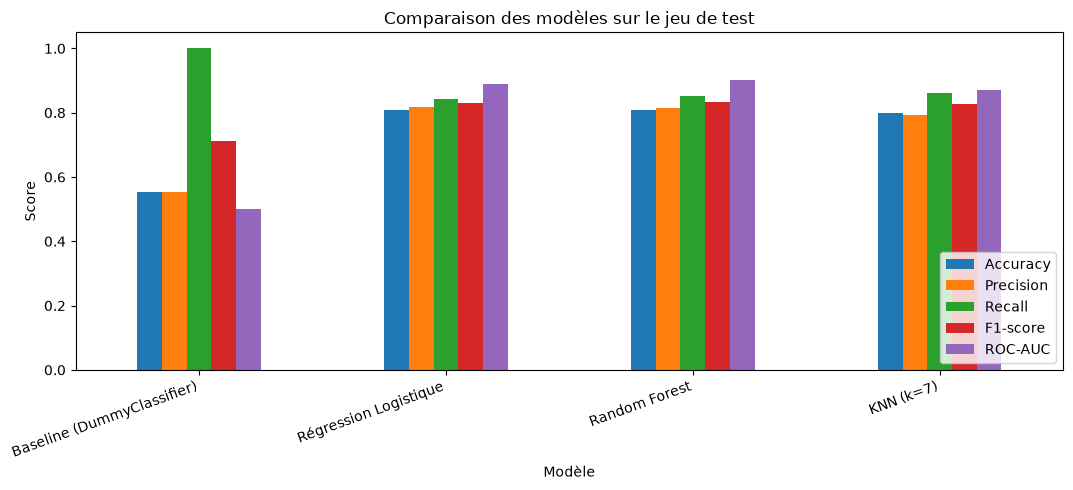

In [52]:
# Comparaison graphique des modèles (Accuracy, Precision, Recall, F1-score, ROC-AUC)
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
ax = results_df[metrics_to_plot].plot(kind="bar", figsize=(11, 5))
ax.set_title("Comparaison des modèles sur le jeu de test")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.set_xticklabels(results_df.index, rotation=20, ha='right')
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

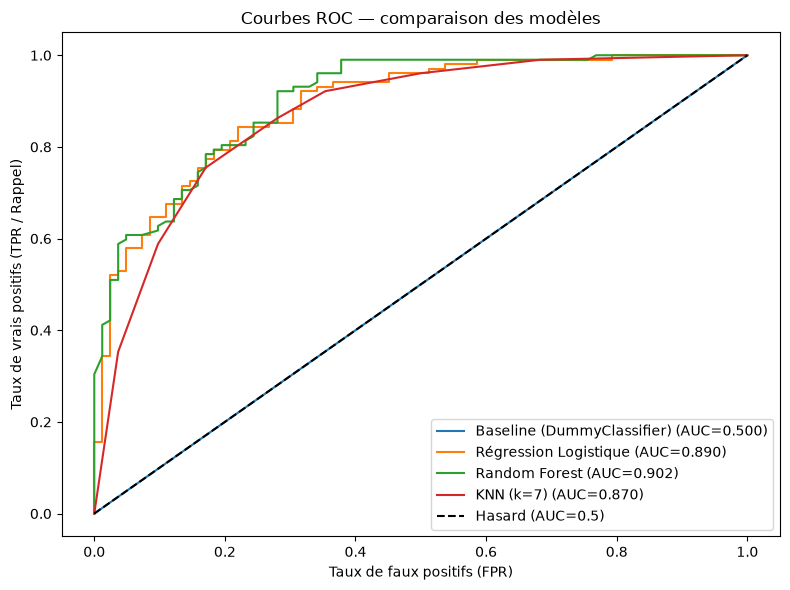

In [53]:
# Courbes ROC comparatives
plt.figure(figsize=(8, 6))
for name, (y_pred, y_proba) in predictions_store.items():
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Hasard (AUC=0.5)')
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR / Rappel)")
plt.title("Courbes ROC — comparaison des modèles")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Interprétation (résultats) :** les modèles appris (Régression Logistique, Random Forest, KNN) doivent être comparés à la baseline. En dépistage, le **rappel** et le **F1-score** sont particulièrement importants, car manquer un patient malade (faux négatif) peut avoir des conséquences graves. Le choix final dépend du compromis entre rappel et précision, et doit toujours inclure une validation humaine.

## Étape 14 — Interprétation des résultats

Nous résumons le meilleur modèle, ses forces/limites, les variables associées et les limites du dataset.

In [54]:
# Meilleur modèle selon F1-score (hors baseline)
best_row = results_df.loc[best_model_name]
print(f"Meilleur modèle (F1-score, hors baseline) : {best_model_name}")
print(best_row.round(4).to_string())

Meilleur modèle (F1-score, hors baseline) : Random Forest
Accuracy     0.8098
Precision    0.8131
Recall       0.8529
F1-score     0.8325
ROC-AUC      0.9023


In [55]:
# Importance des variables (Random Forest) - association avec les prédictions
# Récupérer les noms des colonnes après transformation
pre = rf_pipeline.named_steps['preprocess']
ohe = pre.named_transformers_['cat'].named_steps['encoder']
cat_names = ohe.get_feature_names_out(cat_features)
feature_names = np.concatenate([num_features, cat_names])

importances = rf_pipeline.named_steps['model'].feature_importances_
imp_df = pd.DataFrame({'Variable': feature_names, 'Importance': importances}).sort_values('Importance', ascending=False)

print("Top 10 variables (importance relative, Random Forest) :")
imp_df.head(10)

Top 10 variables (importance relative, Random Forest) :


,Variable,Importance
0,age,0.117354
3,thalch,0.116617
2,chol,0.104600
8,cp_asymptomatic,0.098524
4,oldpeak,0.096284
1,trestbps,0.074067
18,exang_True,0.060336
9,cp_atypical angina,0.047731
17,exang_False,0.039699
6,sex_Female,0.027339


**Interprétation :**
- **Meilleur modèle :** le modèle avec le meilleur F1-score (hors baseline) sur ce jeu de test est indiqué ci-dessus (les résultats exacts dépendent de l'exécution, mais sont calculés à partir du dataset réel).
- **Points forts :** pipeline reproductible (`random_state=42`), séparation train/test stratifiée, imputation et transformations intégrées au pipeline (limite la fuite de données), comparaison avec une baseline.
- **Variables associées aux prédictions :** l'importance Random Forest met en avant certaines variables (ex. liées à la douleur thoracique, aux examens d'effort, au nombre de vaisseaux, etc.) comme plus contributives aux décisions du modèle. Cela reflète des **associations** apprises sur ces données, **pas des relations de cause à effet**.
- **Limites du dataset :** 920 observations seulement, forte proportion de valeurs manquantes sur `ca`, `thal`, `slope` (examens spécialisés absents selon les centres), valeurs 0 invalides corrigées pour `chol`/`trestbps`, données multi-centres hétérogènes, dataset ancien.
- **Risque lié aux manquants :** l'imputation remplace des informations absentes par des estimations (médiane/mode) ; cela peut introduire du bruit, surtout quand plus de 50% des valeurs sont manquantes (ex. `ca`, `thal`).
- **Limites de généralisation :** les performances observées ici ne garantissent pas les mêmes résultats sur une autre population, une autre époque ou un autre contexte clinique (pas de validation externe).

> **Rappel :** projet pédagogique, **pas un dispositif de diagnostic médical**.

## Étape 15 — Conclusion

### Conclusion
Ce projet a suivi les étapes complètes d'un projet de Machine Learning : compréhension du problème, chargement et exploration du dataset, analyse des valeurs manquantes, nettoyage (dont correction des 0 invalides), création de la cible binaire, séparation train/test sans fuite de données, construction de pipelines de prétraitement, entraînement d'une baseline et de plusieurs modèles (Régression Logistique, Random Forest, KNN), prédictions, évaluation et interprétation.

### Points clés
- La cible `target` est dérivée de `num` : 0 = absence, 1 = présence de maladie cardiaque (diagnostic enregistré).
- Les variables explicatives utilisées sont 13 variables cliniques ; `id`, `dataset` et `num` sont exclus.
- Les valeurs manquantes sont nombreuses pour certains examens (`ca`, `thal`, `slope`), ce qui constitue une limite importante malgré une imputation raisonnée.
- Les modèles appris surpassent la baseline, mais toute utilisation réelle nécessiterait une validation rigoureuse, une meilleure qualité de données et une validation externe.

### Avertissement
Ce travail est réalisé dans un cadre universitaire/pédagogique. Il ne remplace pas un avis médical, un diagnostic ou une décision clinique.